# Purchase Intent Baseline (Logistic Regression)
**Goal:** at the first add-to-cart, predict whether the session will end with a later purchase.
**Data:** `intent_train` for fitting, `intent_val` for evaluation. The test set is never opened in this notebook.
**Output:** a Model Score (not a calibrated probability).

## Importing libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import pyarrow 
import pyarrow.parquet as pq
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score,roc_auc_score, precision_recall_curve, PrecisionRecallDisplay, precision_score, recall_score, f1_score


## 2. Load Data and Inspect the Schema
Load train and validation data. Check shape, column names, data types, unique values and missing values.

In [2]:
train = pd.read_parquet("../../data/processed/intent_train.parquet")
val = pd.read_parquet("../../data/processed/intent_val.parquet")

print("TRAIN SHAPE:", train.shape)
print("\nTRAIN COLUMNS:")
print(train.columns.tolist())

print("\nTRAIN DTYPES:")
print(train.dtypes)

print("\nTARGET CANDIDATES:")
print(train.nunique().sort_values())

print("\nMISSING VALUES:")
print(train.isna().sum().sort_values(ascending=False))

TRAIN SHAPE: (590754, 28)

TRAIN COLUMNS:
['user_session', 'user_id', 'session_start', 'first_cart_time', 'split', 'cart_product_ids_at_first_cart_sec', 'cart_category_ids_at_first_cart_sec', 'seconds_to_first_cart', 'views_before_cart', 'has_view_before_cart', 'unique_products_viewed_before_cart', 'unique_categories_viewed_before_cart', 'unique_brands_viewed_before_cart', 'removes_before_cart', 'unique_products_removed_before_cart', 'cart_events_at_first_cart_sec', 'unique_products_carted_at_first_cart_sec', 'has_multi_products_at_first_cart_sec', 'avg_cart_price_at_first_cart_sec', 'avg_viewed_price_before_cart', 'max_viewed_price_before_cart', 'price_ratio_cart_to_view', 'any_cart_brand_at_first_cart_sec', 'hour_of_day_utc', 'day_of_week_utc', 'user_prior_sessions', 'user_prior_purchase_sessions', 'target_purchased_after_cart']

TRAIN DTYPES:
user_session                                             object
user_id                                                  object
session_start 

## 3. Check the Validation Schema
Confirm that validation has the same columns as train.

In [3]:
print("\nVAL SHAPE:", val.shape)
print("\nVAL COLUMNS:")
print(val.columns.tolist())

print("\nTRAIN == VAL COLUMNS:")
print(set(train.columns) == set(val.columns))


VAL SHAPE: (192366, 28)

VAL COLUMNS:
['user_session', 'user_id', 'session_start', 'first_cart_time', 'split', 'cart_product_ids_at_first_cart_sec', 'cart_category_ids_at_first_cart_sec', 'seconds_to_first_cart', 'views_before_cart', 'has_view_before_cart', 'unique_products_viewed_before_cart', 'unique_categories_viewed_before_cart', 'unique_brands_viewed_before_cart', 'removes_before_cart', 'unique_products_removed_before_cart', 'cart_events_at_first_cart_sec', 'unique_products_carted_at_first_cart_sec', 'has_multi_products_at_first_cart_sec', 'avg_cart_price_at_first_cart_sec', 'avg_viewed_price_before_cart', 'max_viewed_price_before_cart', 'price_ratio_cart_to_view', 'any_cart_brand_at_first_cart_sec', 'hour_of_day_utc', 'day_of_week_utc', 'user_prior_sessions', 'user_prior_purchase_sessions', 'target_purchased_after_cart']

TRAIN == VAL COLUMNS:
True


## 4. Define Target and Features
We use an allow-list of 20 numeric features. IDs, raw timestamps, `split` and text ID lists are excluded.
Features describe behavior before the first add-to-cart, a snapshot of that second, and the user's earlier history.

In [4]:
TARGET = "target_purchased_after_cart"

EXCLUDE_COLUMNS = [
    "user_session",
    "user_id",
    "session_start",
    "first_cart_time",
    "split",
    "cart_product_ids_at_first_cart_sec",
    "cart_category_ids_at_first_cart_sec",
    # IDs / leakage columns
]

FEATURE_COLUMNS = [
    "seconds_to_first_cart",
    "views_before_cart",
    "has_view_before_cart",
    "unique_products_viewed_before_cart",
    "unique_categories_viewed_before_cart",
    "unique_brands_viewed_before_cart",
    "removes_before_cart",
    "unique_products_removed_before_cart",
    "cart_events_at_first_cart_sec",
    "unique_products_carted_at_first_cart_sec",
    "has_multi_products_at_first_cart_sec",
    "avg_cart_price_at_first_cart_sec",
    "avg_viewed_price_before_cart",
    "max_viewed_price_before_cart",
    "price_ratio_cart_to_view",
    "any_cart_brand_at_first_cart_sec",
    "hour_of_day_utc",
    "day_of_week_utc",
    "user_prior_sessions",
    "user_prior_purchase_sessions",
]

## 5. Split into Inputs (X) and Target (y)

In [5]:
X_train = train[FEATURE_COLUMNS]
y_train = train[TARGET]

X_val = val[FEATURE_COLUMNS]
y_val = val[TARGET]

## 6. Check Feature Consistency
Train and validation must have the same features in the same order.

In [6]:
assert list(X_train.columns) == list(X_val.columns)
assert X_train.shape[1] == X_val.shape[1]

## 7. Build the Pipelines
Median imputation, then standard scaling, then Logistic Regression.
`pipeline2` uses `class_weight="balanced"` to give more weight to the minority class (buyers).
`pipeline3` Log-Transformed Model
Several features are heavily skewed (e.g. `user_prior_sessions` has a mean of 14 and a maximum of 13,263).
`log1p` reduces the effect of extreme values.

In [7]:
pipeline1 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("modelA", LogisticRegression(
        max_iter=1000
    ))
])


pipeline2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("modelB", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])



pipeline3 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
    ("modelC", LogisticRegression(max_iter=1000))
])


## 8. Train the Baseline Models
All preprocessing statistics are learned from train only, which avoids data leakage from validation.

In [8]:
pipeline1.fit(X_train, y_train)

pipeline2.fit(X_train, y_train)

pipeline3.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('log', FunctionTransformer(func=<ufunc 'log1p'>)),
                ('scaler', StandardScaler()),
                ('modelC', LogisticRegression(max_iter=1000))])

## 9. Validation Evaluation

In [9]:

val_scores = pipeline1.predict_proba(X_val)[:, 1]
val_scores2 = pipeline2.predict_proba(X_val)[:, 1]
val_scores3 = pipeline3.predict_proba(X_val)[:, 1]

## 10. Compare Models on Validation
The main metric is **PR-AUC** because the classes are imbalanced. We also report ROC-AUC, and precision, recall and F1
at threshold 0.5 and at the best-F1 threshold. The best-F1 threshold is informative only, not final.

In [10]:

models = {"no_class_weight": pipeline1, "balanced": pipeline2, "log1p": pipeline3}

def evaluate(y, score, threshold):
    pred = (score >= threshold).astype(int)
    return {"threshold": float(threshold),
            "precision": float(precision_score(y, pred, zero_division=0)),
            "recall": float(recall_score(y, pred, zero_division=0)),
            "f1": float(f1_score(y, pred, zero_division=0))}

results = {}
for name, model in models.items():
    score = model.predict_proba(X_val)[:, 1]
    train_score = model.predict_proba(X_train)[:, 1]
    p, r, t = precision_recall_curve(y_val, score)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    results[name] = {"train_pr_auc": float(average_precision_score(y_train, train_score)),
                     "pr_auc": float(average_precision_score(y_val, score)),
                     "roc_auc": float(roc_auc_score(y_val, score)),
                     "at_0.5": evaluate(y_val, score, 0.5),
                     "at_best_f1": evaluate(y_val, score, t[np.argmax(f1)])}

comparison = pd.DataFrame({
    n: {"train PR-AUC": r["train_pr_auc"], "val PR-AUC": r["pr_auc"], "val ROC-AUC": r["roc_auc"],
        "best threshold": r["at_best_f1"]["threshold"], "precision": r["at_best_f1"]["precision"],
        "recall": r["at_best_f1"]["recall"], "F1": r["at_best_f1"]["f1"]}
    for n, r in results.items()}).T.round(4)
print(comparison.to_string())

best = max(results, key=lambda n: results[n]["pr_auc"])
print("Selected:", best)

                 train PR-AUC  val PR-AUC  val ROC-AUC  best threshold  precision  recall      F1
no_class_weight        0.1771      0.1854       0.6002          0.1213     0.1575  0.6962  0.2568
balanced               0.1754      0.1813       0.5958          0.4783     0.1541  0.7330  0.2547
log1p                  0.1852      0.1909       0.6107          0.1267     0.1663  0.6100  0.2613
Selected: log1p


## 11. Precision-Recall Curves and Coefficients
Coefficients refer to log-transformed, standardized features. They show associations, not causes.
Correlated features (such as view counts) should be interpreted together.

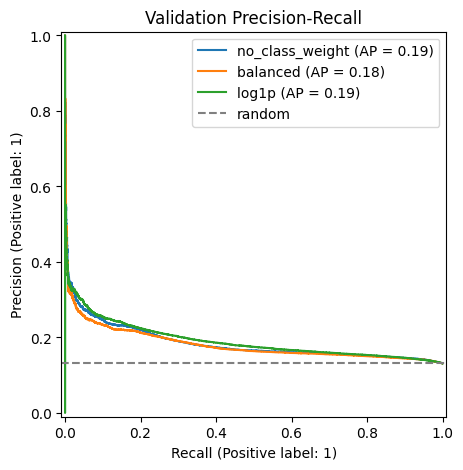

                                 feature  coefficient
                     user_prior_sessions    -0.334489
                       views_before_cart     0.328230
                    has_view_before_cart    -0.303110
            user_prior_purchase_sessions     0.293743
                   seconds_to_first_cart     0.184473
            avg_viewed_price_before_cart     0.179958
      unique_products_viewed_before_cart    -0.157916
     unique_products_removed_before_cart     0.123441
            max_viewed_price_before_cart    -0.121356
        avg_cart_price_at_first_cart_sec     0.101168
                         day_of_week_utc     0.072712
           cart_events_at_first_cart_sec     0.059813
    unique_categories_viewed_before_cart    -0.042205
unique_products_carted_at_first_cart_sec    -0.033357
                     removes_before_cart    -0.032492
                         hour_of_day_utc     0.032450
        any_cart_brand_at_first_cart_sec     0.014873
        unique_brands_viewed

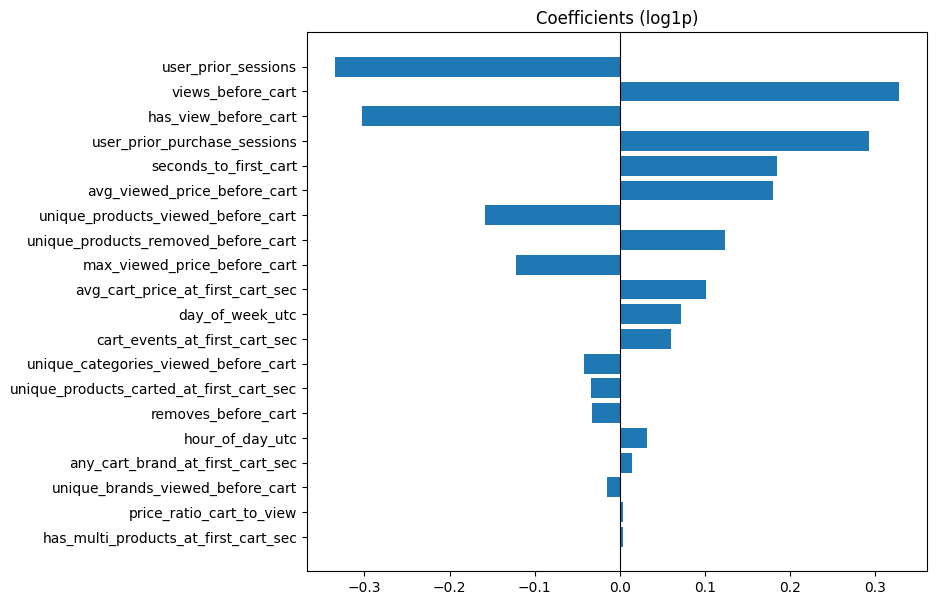

In [11]:
OUT = Path("../../reports/intent_baseline")
OUT.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 5))
for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(model, X_val, y_val, name=name, ax=ax)
ax.axhline(y_val.mean(), ls="--", color="gray", label="random")
ax.set_title("Validation Precision-Recall")
ax.legend()
fig.savefig(OUT / "pr_curve_val.png", dpi=150, bbox_inches="tight")
plt.show()

coefs = pd.DataFrame({"feature": FEATURE_COLUMNS,
                      "coefficient": models[best][-1].coef_[0]})
coefs = coefs.sort_values("coefficient", key=abs, ascending=False)
print(coefs.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(coefs["feature"][::-1], coefs["coefficient"][::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_title(f"Coefficients ({best})")
fig.savefig(OUT / "coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Save Outputs
Metrics, feature list, a sample input and the trained pipeline, for the model comparison and the API.

In [12]:
import json, joblib
from pathlib import Path

OUT = Path("../../reports/intent_baseline")
OUT.mkdir(parents=True, exist_ok=True)

def save_json(obj, filename):
    (OUT / filename).write_text(json.dumps(obj, indent=2), encoding="utf-8")

save_json({"selected": best, "primary_metric": "pr_auc", "results": results,
           "coefficients": coefs.to_dict(orient="records"),
           "rows": {"train": len(train), "val": len(val)},
           "intercept": float(models[best][-1].intercept_[0]),
           "sklearn_version": sklearn.__version__,
           "assumptions": ["Median imputation and scaling fitted on train only",
                "log1p applied before scaling" if best == "log1p" else "No log transform",
                "Hour and weekday treated as linear numbers",
                "Score is not calibrated; threshold is not final"]},
           "baseline_metrics.json")
save_json({"features": FEATURE_COLUMNS, "target": TARGET}, "feature_columns.json")

row = X_val.dropna().iloc[[0]]
save_json(json.loads(row.to_json(orient="records"))[0], "sample_input.json")
joblib.dump(models[best], OUT / "baseline_pipeline.joblib")
print(sorted(f.name for f in OUT.iterdir()))

['baseline_metrics.json', 'baseline_pipeline.joblib', 'coefficients.png', 'feature_columns.json', 'pr_curve_val.png', 'sample_input.json']


## 13. Verify the Saved Model
Reload the pipeline and score one sample to confirm it works.

In [13]:
loaded = joblib.load(OUT / "baseline_pipeline.joblib")
print(loaded.predict_proba(row)[0, 1])   

0.1321229931412851
